<a href="https://colab.research.google.com/github/liangjingyi1211/neural-search-ranking/blob/main/notebooks/03_embedding_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · FiQA BGE Small 对比学习微调（In-batch Negatives）

**研究问题**：基于 FiQA train 的 `(query, positive document)`，使用 Multiple Negatives Ranking Loss (InfoNCE) 全参数微调 `BAAI/bge-small-en-v1.5`，能否提升 FiQA dev 检索？

**实验约束**：只用 train 标注构造训练对；dev 只用于评测；不使用 test；不额外挖掘 Hard Negatives（留给 Notebook 04）；用与 02 一致的完整 corpus、BGE query **不加 instruction**、`normalize_embeddings=True`、`FAISS IndexFlatIP`、Top-100、BEIR 评测。文档文本仍为 `title + ' ' + text`。

配置：T4 GPU，推荐先跑一轮 1 epoch、batch 8、FP16、梯度累积 2。所有报告由实际代码计算。**Notebook 只作为实验入口，后续把稳定的训练和评测逻辑整理到 `src/`。**

## 0. 初始化 Colab 项目

在 Colab 菜单选 **Runtime → Change runtime type → T4 GPU**。每次运行时重启后，从上往下重新执行。

In [2]:
import os, sys, json, time, random, shutil, hashlib
from pathlib import Path
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROJECT_DIR = Path('/content/neural-search-ranking')
REPO_URL = 'https://github.com/liangjingyi1211/neural-search-ranking.git'
if not (PROJECT_DIR / '.git').exists():
    !git clone {REPO_URL}
os.chdir(PROJECT_DIR)
for path in ['reports', 'checkpoints', 'data']:
    (PROJECT_DIR / path).mkdir(exist_ok=True, parents=True)
assert torch.cuda.is_available(), '请先在 Runtime 中启用 GPU；训练建议使用 T4'
print('Project:', os.getcwd())
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Project: /content/neural-search-ranking
GPU: Tesla T4
PyTorch: 2.14.1+cu130


## 1. 安装与核查依赖

不手动重装 Colab 预装的 PyTorch。初次安装后若提示重启运行时，重启并从第 0 步重新运行。

In [3]:
%pip install -q -U sentence-transformers datasets accelerate faiss-cpu beir pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [4]:
import sentence_transformers, transformers, datasets, accelerate, faiss, beir
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers
from datasets import Dataset
from beir import util
from beir.datasets.data_loader import GenericDataLoader
from beir.retrieval.evaluation import EvaluateRetrieval
import pandas as pd
import matplotlib.pyplot as plt

versions = {"python": sys.version.split()[0], "torch": torch.__version__,
            "sentence_transformers": sentence_transformers.__version__,
            "transformers": transformers.__version__, "datasets": datasets.__version__,
            "accelerate": accelerate.__version__, "faiss": faiss.__version__}
print(json.dumps(versions, indent=2))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "sentence_transformers": "6.2.0",
  "transformers": "5.22.1",
  "datasets": "5.1.0",
  "accelerate": "1.15.0",
  "faiss": "1.15.1"
}


/tmp/ipykernel_1407/775508457.py:2: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
/tmp/ipykernel_1407/775508457.py:3: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


## 2. 读取 FiQA train / dev

`GenericDataLoader` 不应在同一实例上反复加载不同 split。train / dev 分开建立 loader；文档库是相同的完整 corpus。

In [5]:
url = 'https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/fiqa.zip'
data_path = util.download_and_unzip(url, str(PROJECT_DIR / 'data'))
corpus, train_queries, train_qrels = GenericDataLoader(data_folder=data_path).load(split='train')
_, dev_queries, dev_qrels = GenericDataLoader(data_folder=data_path).load(split='dev')
assert not (set(train_queries) & set(dev_queries)), 'train/dev query ID 有重叠，暂停检查'
assert all(d in corpus for rel in train_qrels.values() for d in rel)
assert all(d in corpus for rel in dev_qrels.values() for d in rel)
print('Corpus:', len(corpus), 'Train queries:', len(train_queries), 'Dev queries:', len(dev_queries))
print('Train labels:', sum(len(v) for v in train_qrels.values()))

/content/neural-search-ranking/data/fiqa.zip:   0%|          | 0.00/17.1M [00:00<?, ?iB/s]

  0%|          | 0/57638 [00:00<?, ?it/s]

  0%|          | 0/57638 [00:00<?, ?it/s]

Corpus: 57638 Train queries: 5500 Dev queries: 500
Train labels: 14166


## 3. 构造 Query–Positive 训练对

每个训练 Query 选一个带正相关性标签的文档（如有多个，先选相关性最高者，再用确定性随机选择打破平局）。**不使用 dev/test 标签**。本阶段不手工声明任何未标注的负例。

同批次其他 Query 的正样本文档被用于 **in-batch negatives**，但因为 FiQA 相关性标注不一定完备，仍存在 *false negative* 风险；`NO_DUPLICATES` 只能避免相同文本重复，无法完全排除语义上相关的不同文档。

In [6]:
def make_document(did):
    doc = corpus[did]
    return ((doc.get('title') or '') + ' ' + (doc.get('text') or '')).strip()

rng = random.Random(SEED)
pairs = []
for qid in sorted(train_qrels):
    if qid not in train_queries:
        continue
    positive_ids = [d for d, score in train_qrels[qid].items() if score > 0 and d in corpus]
    if not positive_ids:
        continue
    best_score = max(train_qrels[qid][d] for d in positive_ids)
    best_ids = sorted(d for d in positive_ids if train_qrels[qid][d] == best_score)
    did = rng.choice(best_ids)
    q = train_queries[qid].strip()
    p = make_document(did)
    if q and p:
        pairs.append((q, p))

# 对完全重复的 query/document pair 去重
pairs = list(dict.fromkeys(pairs))
train_dataset = Dataset.from_dict({
    'anchor': [q for q, p in pairs],
    'positive': [p for q, p in pairs],
})
print('Training pairs:', len(train_dataset))
print('Example query:', train_dataset[0]['anchor'])
print('Positive passage:', train_dataset[0]['positive'][:350])
assert len(train_dataset) > 1000
assert len(train_dataset) <= len(train_queries)

Training pairs: 5489
Example query: What is considered a business expense on a business trip?
Positive passage: The IRS Guidance pertaining to the subject.  In general the best I can say is your business expense may be deductible.  But it depends on the circumstances and what it is you want to deduct. Travel Taxpayers who travel away from home on business may deduct related   expenses, including the cost of reaching their destination, the cost   of lodging a


## 4. 理解本次训练的张量和损失函数

批次大小为 `B` 时，编码后 `Q, D` 形状均为 `[B, 384]`，计算相似度矩阵 `S = Q @ D.T`，得到 `[B, B]`。理想情况下，第 `i` 个 Query 对应第 `i` 篇正样本文档：相似度矩阵**对角线**是正样本，其余为 Batch 内负样本。

损失（示意）：

$$\mathcal{L}= -\frac{1}{B}\sum_{i=1}^{B}\log \frac{\exp(s(q_i,d_i)/	au)}{\sum_{j=1}^{B}\exp(s(q_i,d_j)/	au)}$$

用官方 `MultipleNegativesRankingLoss`，而不是手写训练循环。**梯度累积不等于增加同一批次的负样本数量**：batch=8、累积=2，单次对比损失仍只看到 8 组正样本（除非使用专门的缓存式损失）。

## 5. 训练配置：先跑轻量正式实验

- 基座：BGE Small，**全参数微调**（不是 LoRA）
- Batch=8，gradient accumulation=2，1 epoch，LR=2e-5，FP16
- 训练阶段 `max_seq_length=256` 控制显存；检索评测阶段恢复到 02 使用的 512，以保证推理截断协议一致。训练长度与推理长度不同是已记录的实验设计，并非隐藏变量。
- 为避免与旧版 02 不可比，Query **不加额外 instruction**。如果你在 02 实际修改过 Query 前缀或文档拼接方式，请先同步这里的设置。

In [7]:
MODEL_NAME = 'BAAI/bge-small-en-v1.5'
MODEL_DIR = PROJECT_DIR / 'checkpoints' / 'fiqa_bge_small_inbatch_seed42'
OUTPUT_DIR = PROJECT_DIR / 'checkpoints' / 'trainer_fiqa_inbatch'
CONFIG = {
    'seed': SEED, 'model': MODEL_NAME, 'dataset': 'fiqa',
    'train_split': 'train', 'eval_split': 'dev', 'method': 'MNRL_inbatch',
    'epochs': 1, 'batch_size': 8, 'gradient_accumulation_steps': 2,
    'lr': 2e-5, 'warmup_ratio': 0.1, 'train_max_seq_length': 256,
    'eval_max_seq_length': 512, 'fp16': True, 'top_k': 100,
    'query_instruction': '', 'normalize_embeddings': True
}
print(json.dumps(CONFIG, indent=2))
model = SentenceTransformer(MODEL_NAME, device='cuda')
print('Embedding size:', model.get_sentence_embedding_dimension())
model.max_seq_length = CONFIG['train_max_seq_length']
print('Train max length:', model.max_seq_length)

{
  "seed": 42,
  "model": "BAAI/bge-small-en-v1.5",
  "dataset": "fiqa",
  "train_split": "train",
  "eval_split": "dev",
  "method": "MNRL_inbatch",
  "epochs": 1,
  "batch_size": 8,
  "gradient_accumulation_steps": 2,
  "lr": 2e-05,
  "warmup_ratio": 0.1,
  "train_max_seq_length": 256,
  "eval_max_seq_length": 512,
  "fp16": true,
  "top_k": 100,
  "query_instruction": "",
  "normalize_embeddings": true
}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding size: 384
Train max length: 256


/tmp/ipykernel_1407/1991012394.py:14: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print('Embedding size:', model.get_sentence_embedding_dimension())


## 6. 启动对比学习训练

单卡 T4 优先尝试 batch=8。若出现 CUDA OOM：**重新运行训练构建单元格前先重启运行时**，然后将 `batch_size` 改为 4，同时酌情降低训练最大长度。不要把训练中断后残留的部分状态当作正式结果。

In [8]:
loss = losses.MultipleNegativesRankingLoss(model)
args = SentenceTransformerTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=CONFIG['epochs'],
    per_device_train_batch_size=CONFIG['batch_size'],
    gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
    learning_rate=CONFIG['lr'],
    warmup_ratio=CONFIG['warmup_ratio'],
    fp16=CONFIG['fp16'],
    bf16=False,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    eval_strategy='no',
    save_strategy='no',
    logging_steps=20,
    logging_first_step=True,
    report_to='none',
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
)
trainer = SentenceTransformerTrainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    loss=loss,
)
start_train = time.perf_counter()
train_output = trainer.train()
train_seconds = time.perf_counter() - start_train
print('Training done, seconds:', round(train_seconds, 1))
print('Global steps:', train_output.global_step)
print('Training loss:', train_output.training_loss)

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
1,0.749120
20,0.517432
40,0.371782
60,0.300518
80,0.239822
100,0.225362
120,0.238314
140,0.238425
160,0.194024
180,0.271634


Training done, seconds: 98.9
Global steps: 344
Training loss: 0.261754737603803


## 7. 保存训练日志、曲线和模型

模型放进 `.gitignore` 忽略的 `checkpoints/`；GitHub 只提交轻量训练日志与结果。Colab 回收会删除 `/content`，因此**建议随后复制模型到 Google Drive**。

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

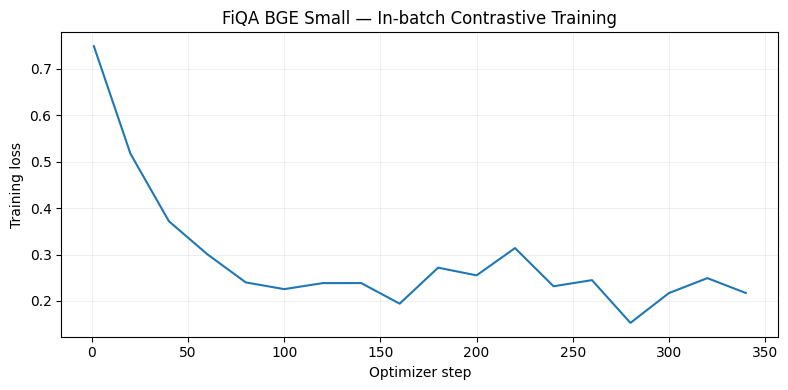

Model saved: /content/neural-search-ranking/checkpoints/fiqa_bge_small_inbatch_seed42


In [9]:
model.max_seq_length = CONFIG['eval_max_seq_length']
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save(str(MODEL_DIR))

log_history = trainer.state.log_history
train_logs = [x for x in log_history if 'loss' in x and 'step' in x]
report_dir = PROJECT_DIR / 'reports'
report_dir.mkdir(parents=True, exist_ok=True)
(report_dir / 'fiqa_bge_inbatch_train_logs.json').write_text(
    json.dumps(log_history, indent=2, default=str), encoding='utf-8'
)
(report_dir / 'fiqa_bge_inbatch_config.json').write_text(
    json.dumps({'config':CONFIG,'versions':versions,'train_pairs':len(train_dataset),
                'train_seconds':train_seconds}, indent=2), encoding='utf-8'
)
if train_logs:
    plt.figure(figsize=(8,4))
    plt.plot([x['step'] for x in train_logs], [x['loss'] for x in train_logs])
    plt.xlabel('Optimizer step')
    plt.ylabel('Training loss')
    plt.title('FiQA BGE Small — In-batch Contrastive Training')
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(report_dir / 'fiqa_bge_inbatch_train_loss.png', dpi=160)
    plt.show()
print('Model saved:', MODEL_DIR)

## 8. 将模型备份到 Google Drive（推荐）

下面是可选但建议执行的操作；Drive 文件可能较大，不要放进 GitHub。以后复现时如果模型已经存在可以从 Drive 加载。

In [10]:
BACKUP_TO_DRIVE = True
if BACKUP_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    backup_dir = Path('/content/drive/MyDrive/neural-search-ranking/checkpoints/fiqa_bge_small_inbatch_seed42')
    shutil.copytree(MODEL_DIR, backup_dir, dirs_exist_ok=True)
    print('Saved to:', backup_dir)

Mounted at /content/drive
Saved to: /content/drive/MyDrive/neural-search-ranking/checkpoints/fiqa_bge_small_inbatch_seed42


## 9. 用新模型重新编码 **完整 Corpus** 并建立 FAISS 索引

与 02 一样，文档数约 57,638，向量维度 384。**模型训练后文档向量已经改变，不能复用 02 的旧 FAISS 索引。** 测试采用精确 `IndexFlatIP`。此单元格可能是训练后最耗时的推理环节。

In [11]:
doc_ids = list(corpus.keys())
doc_texts = [make_document(did) for did in doc_ids]
query_ids = list(dev_queries.keys())
query_texts = [dev_queries[qid] for qid in query_ids]
model.eval()

start = time.perf_counter()
doc_embeddings = model.encode(
    doc_texts, batch_size=64, show_progress_bar=True,
    normalize_embeddings=True, convert_to_numpy=True
)
if torch.cuda.is_available(): torch.cuda.synchronize()
encode_seconds = time.perf_counter() - start
doc_embeddings = np.ascontiguousarray(doc_embeddings, dtype=np.float32)
assert doc_embeddings.shape == (len(corpus), 384)

start = time.perf_counter()
index = faiss.IndexFlatIP(384)
index.add(doc_embeddings)
index_seconds = time.perf_counter() - start
print('Embeddings:', doc_embeddings.shape, 'Index size:', index.ntotal)
print('Corpus encode s:', round(encode_seconds, 2), 'Build index s:', round(index_seconds, 2))
# 避免重复持有大数组
del doc_embeddings

Batches:   0%|          | 0/901 [00:00<?, ?it/s]

Embeddings: (57638, 384) Index size: 57638
Corpus encode s: 150.29 Build index s: 0.07


## 10. 检索 Dev Top-100

`query_embeddings` 形状 `(500, 384)`；FAISS 的 `scores`、`indices` 形状 `(500, 100)`。FAISS 位置需映射回原始 doc_id。

In [12]:
TOP_K = CONFIG['top_k']
query_embeddings = model.encode(
    query_texts, batch_size=64, show_progress_bar=True,
    normalize_embeddings=True, convert_to_numpy=True
)
query_embeddings = np.ascontiguousarray(query_embeddings, dtype=np.float32)
scores, ids = index.search(query_embeddings, TOP_K)
assert scores.shape == (len(query_ids), TOP_K)
results = {
    qid: {doc_ids[int(idx)]: float(score)
          for idx, score in zip(ids[row], scores[row]) if idx >= 0}
    for row, qid in enumerate(query_ids)
}
print('Query embedding shape:', query_embeddings.shape)
print('Retrieved query count:', len(results))

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Query embedding shape: (500, 384)
Retrieved query count: 500


## 11. BEIR Dev 评测并和 02 严格对照

这里固定 `dev_qrels` 和 02 的 Top-100 评测规则。预训练指标优先从你保存的 `reports/fiqa_bge_small_dev.json` 加载；如果找不到，使用之前实际记录的四项数值作为**手工参考值**（不会伪装成这次计算）。

In [13]:
ndcg, _map, recall, precision = EvaluateRetrieval.evaluate(
    dev_qrels, results, k_values=[10,100]
)
mrr = EvaluateRetrieval.evaluate_custom(
    dev_qrels, results, k_values=[10], metric='mrr'
)
ft_metrics = {
    'ndcg_10': ndcg['NDCG@10'],
    'recall_10': recall['Recall@10'],
    'recall_100': recall['Recall@100'],
    'mrr_10': mrr['MRR@10'],
}

baseline_file = report_dir / 'fiqa_bge_small_dev.json'
if baseline_file.exists():
    baseline_report = json.loads(baseline_file.read_text(encoding='utf-8'))
    baseline_metrics = {k: baseline_report[k] for k in ft_metrics}
    baseline_source = str(baseline_file)
else:
    baseline_metrics = {
        'ndcg_10': 0.39916, 'recall_10': 0.46559,
        'recall_100': 0.70287, 'mrr_10': 0.47566
    }
    baseline_source = 'previous user-provided 02 run (manual reference)'

rows = []
for metric in ft_metrics:
    old, new = baseline_metrics[metric], ft_metrics[metric]
    rows.append({'metric': metric, 'pretrained': old,
                 'finetuned': new, 'absolute_delta': round(new-old,5),
                 'relative_change_pct': round((new/old-1)*100,2) if old else None})
comparison = pd.DataFrame(rows)
print('Baseline source:', baseline_source)
display(comparison)
print('Finetuned metrics:', json.dumps(ft_metrics, indent=2))

Baseline source: previous user-provided 02 run (manual reference)


,metric,pretrained,finetuned,absolute_delta,relative_change_pct
0,ndcg_10,0.39916,0.39826,-0.00090,-0.23
1,recall_10,0.46559,0.45061,-0.01498,-3.22
2,recall_100,0.70287,0.71504,0.01217,1.73
3,mrr_10,0.47566,0.48336,0.00770,1.62


Finetuned metrics: {
  "ndcg_10": 0.39826,
  "recall_10": 0.45061,
  "recall_100": 0.71504,
  "mrr_10": 0.48336
}


## 12. 绘图与保存正式实验报告

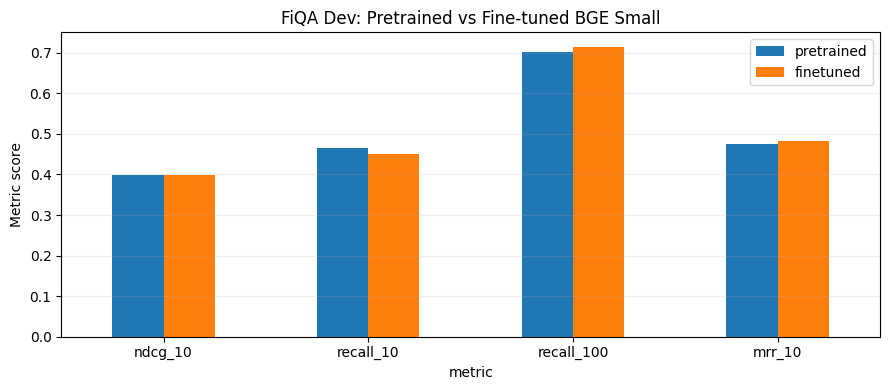

Report: /content/neural-search-ranking/reports/fiqa_bge_inbatch_dev.json


In [14]:
ax = comparison.set_index('metric')[['pretrained','finetuned']].plot.bar(figsize=(9,4), rot=0)
ax.set_ylabel('Metric score')
ax.set_title('FiQA Dev: Pretrained vs Fine-tuned BGE Small')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig(report_dir / 'fiqa_bge_pretrained_vs_inbatch.png', dpi=160)
plt.show()

report = {
    'dataset':'fiqa', 'split':'dev', 'model':MODEL_NAME,
    'method':'finetuned_MNRL_inbatch', 'seed':SEED,
    'train_queries':len(train_queries), 'train_pairs':len(train_dataset),
    'dev_queries':len(dev_queries), 'corpus_size':len(corpus),
    'config':CONFIG, 'versions':versions,
    'train_seconds':round(train_seconds,2),
    'corpus_encoding_seconds':round(encode_seconds,2),
    'faiss_index_build_seconds':round(index_seconds,2),
    'baseline_source':baseline_source, 'baseline_metrics':baseline_metrics,
    'metrics':ft_metrics, 'comparison':rows,
    'limitations':[
        'FiQA qrels may be incomplete: in-batch negatives can contain false negatives',
        'One seed and one epoch: more seeds and cross-domain tests pending',
        'No hard-negative mining; trained with in-batch negatives only'
    ]
}
(report_dir / 'fiqa_bge_inbatch_dev.json').write_text(
    json.dumps(report, indent=2), encoding='utf-8'
)
print('Report:', report_dir / 'fiqa_bge_inbatch_dev.json')

## 13. 可选：保存新的 FAISS 索引至 Drive

训练后的索引不要覆盖 02 的预训练索引，后续的比较和部署需要保留两个版本。保存索引文件、doc_id 顺序及模型信息，不直接保存全量文本到 GitHub。

In [15]:
SAVE_INDEX_TO_DRIVE = True
if SAVE_INDEX_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    dest = Path('/content/drive/MyDrive/neural-search-ranking/artifacts/fiqa_bge_inbatch_seed42')
    dest.mkdir(parents=True, exist_ok=True)
    faiss.write_index(index, str(dest / 'index_flatip.faiss'))
    (dest / 'doc_ids.json').write_text(json.dumps(doc_ids), encoding='utf-8')
    (dest / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
    print('Saved index + doc_ids:', dest)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved index + doc_ids: /content/drive/MyDrive/neural-search-ranking/artifacts/fiqa_bge_inbatch_seed42


## 14. 如何保存到 GitHub / 下一阶段

1. 使用 Colab **File → Save a copy in GitHub**，路径：`notebooks/03_embedding_training.ipynb`。
2. 只推送：`reports/fiqa_bge_inbatch_dev.json`、训练配置 JSON、训练日志与曲线图片；**不要推送** `checkpoints/`、`data/`、Drive 模型权重及索引。
3. 若 Notebook 当前仍然位于 Colab 编辑器，而不是仓库文件系统，保存到 GitHub 菜单才会上传 Notebook；Terminal `git add` 无法自动识别编辑器中的 Notebook。
4. 将 **微调后四项指标 + 对比表 + loss 曲线** 发回对话。若指标下降，也保留结果，分析训练集样本量、batch 内假负例、领域过拟合和超参数，不要删除不理想的实验。

**下一阶段 04**：加入显式 Random / BM25 / Dense hard negatives，公平对比数据采样对检索效果的影响。